In [1]:
import starfile
from pathlib import Path
import seaborn as sns
import numpy as np
from scipy.spatial import cKDTree
import matplotlib.pyplot as plt


A module that was compiled using NumPy 1.x cannot be run in
NumPy 2.1.3 as it may crash. To support both 1.x and 2.x
versions of NumPy, modules must be compiled with NumPy 2.0.
Some module may need to rebuild instead e.g. with 'pybind11>=2.12'.

If you are a user of the module, the easiest solution will be to
downgrade to 'numpy<2' or try to upgrade the affected module.
We expect that some modules will need time to support NumPy 2.

Traceback (most recent call last):  File "/usr/lib/python3.10/runpy.py", line 196, in _run_module_as_main
    return _run_code(code, main_globals, None,
  File "/usr/lib/python3.10/runpy.py", line 86, in _run_code
    exec(code, run_globals)
  File "/usr/lib/python3/dist-packages/ipykernel_launcher.py", line 16, in <module>
    app.launch_new_instance()
  File "/usr/lib/python3/dist-packages/traitlets/config/application.py", line 846, in launch_instance
    app.start()
  File "/usr/lib/python3/dist-packages/ipykernel/kernelapp.py", line 677, in start
    s

AttributeError: _ARRAY_API not found

ImportError: numpy.core.multiarray failed to import

In [2]:
tomograms_base = Path('/goliath/processing/Gouaux/CJS/BestTomo/ProcessingCJS/tomograms/15F1_tomograms/TOP_TOMOS/')
tomograms = list(tomograms_base.glob('*/best_alignment/aunps/presynatpticmembranes_1.txt'))
tomograms = [a.parent.parent.parent.name for a in tomograms]
tomograms

['20231017_EGmilled24-2_51',
 '20240111_WaffleHipp_198',
 '20231017_EGmilled24-2_60',
 '20241030_AMmilled12-1_15',
 '20240111_WaffleHipp_96',
 '20241030_AMmilled12-1_12',
 '20231026_HippAu_26',
 '20231017_HippAu_132',
 '20231017_EGmilled24-2_68',
 '20231017_EGmilled24-2_54']

In [3]:
aunp_dfs = {}
for tomogram in tomograms:

    basefolder = tomograms_base
    aunp_star = basefolder / tomogram / "best_alignment" / "aunps" / "aunp_tm.star"
    presynaptic_txts = list((basefolder / tomogram / "best_alignment" / "aunps").glob("presynatpticmembranes*.txt"))
    postsynaptic_txts = list((basefolder / tomogram / "best_alignment" / "aunps").glob("postsynapticmembranes*.txt"))

    aunp_data = starfile.read(aunp_star)
    presynaptic_data = [np.loadtxt(f) for f in presynaptic_txts]
    presynaptic_data = np.concatenate(presynaptic_data)
    presynaptic_data.shape
    postsynaptic_data = [np.loadtxt(f) for f in postsynaptic_txts]
    postsynaptic_data = np.concatenate(postsynaptic_data)
    pre_kd = cKDTree(presynaptic_data)
    post_kd = cKDTree(postsynaptic_data)

    aunp_pos = aunp_data[["faTM_PeakX", "faTM_PeakY", "faTM_PeakZ"]].values
    aunp_data["Size"] = aunp_data["faTomo_gaussianFitSigmaX"] * aunp_data["faTomo_gaussianFitSigmaY"] * aunp_data["faTomo_gaussianFitSigmaZ"]
    pre_dists, pre_idxs = pre_kd.query(aunp_pos)
    post_dists, post_idxs = post_kd.query(aunp_pos)
    aunp_data["pre_dist"] = pre_dists
    aunp_data["post_dist"] = post_dists

    aunp_dfs[tomogram] = aunp_data


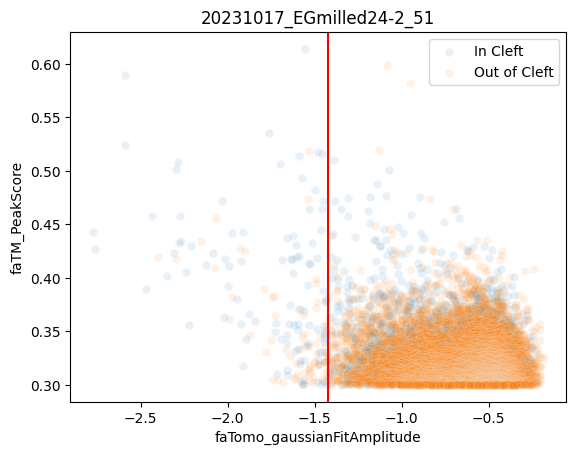

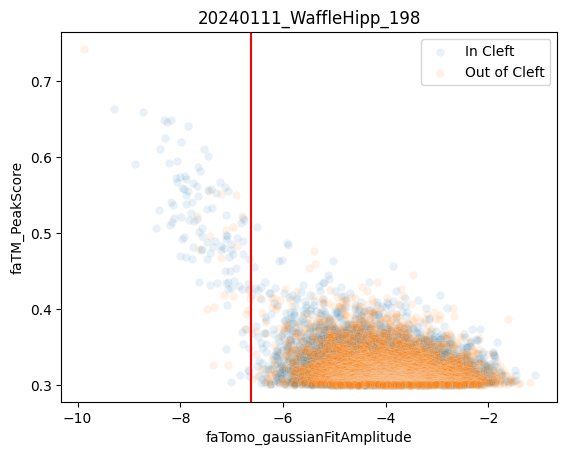

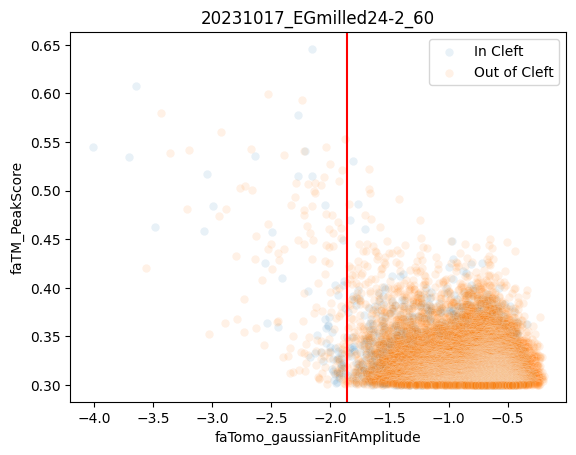

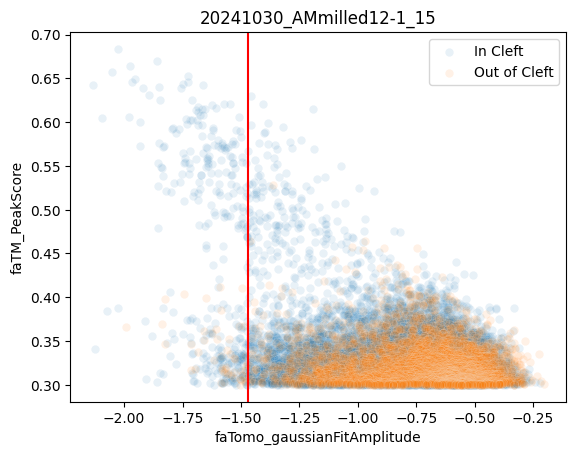

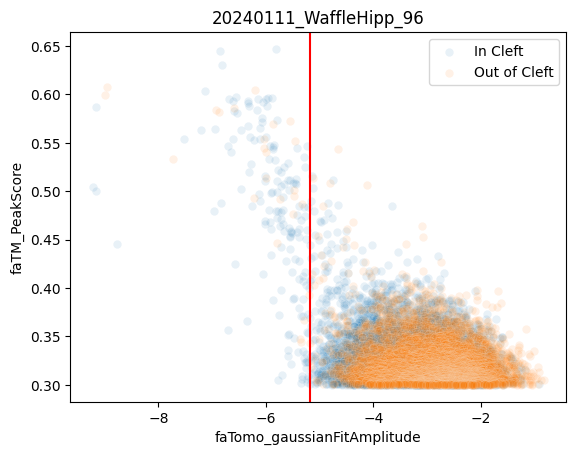

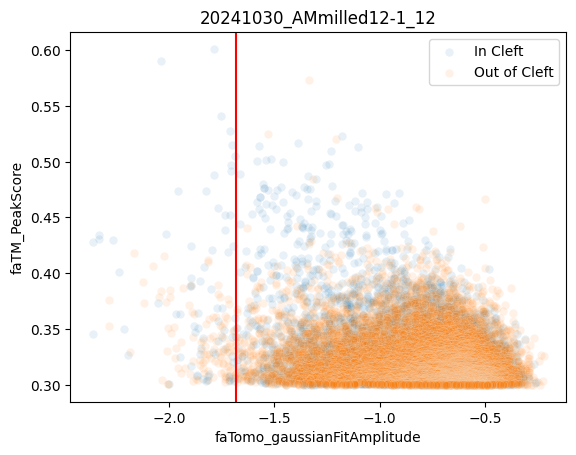

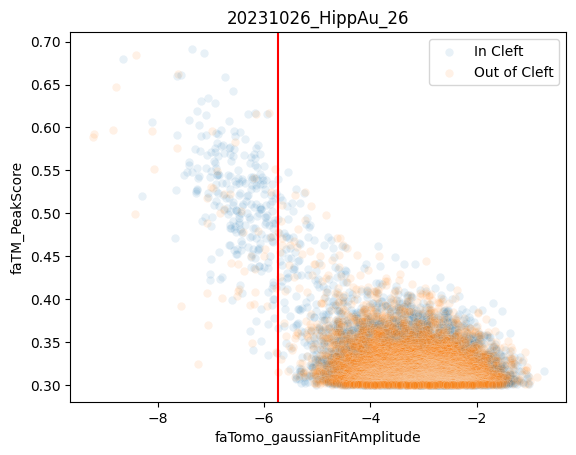

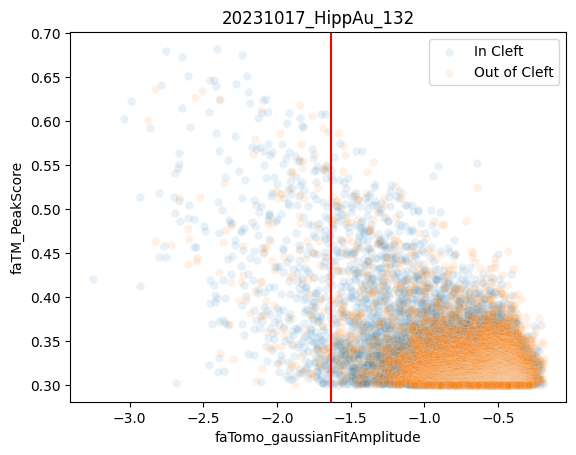

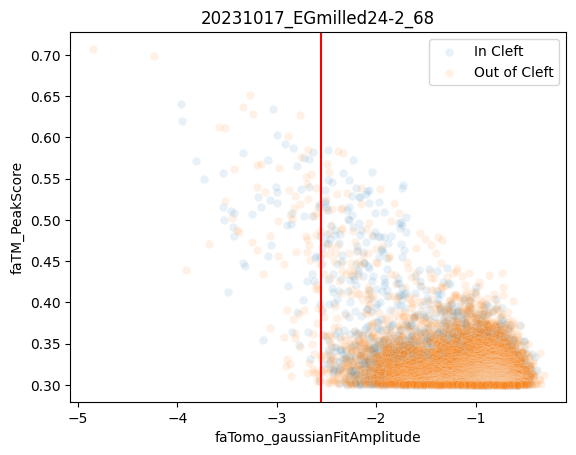

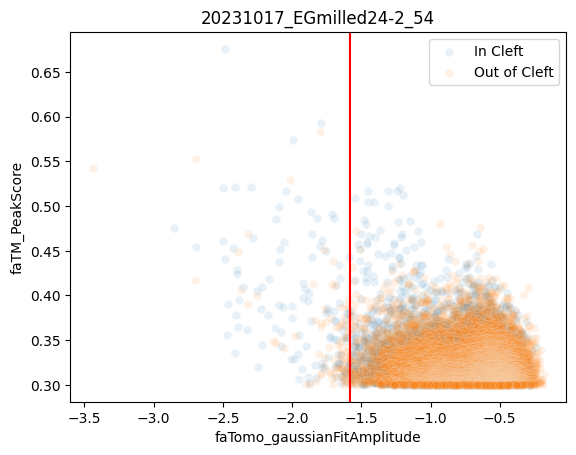

In [4]:
for tomogram in tomograms:
    aunp_data = aunp_dfs[tomogram]
    in_cleft_aunps = aunp_data[(aunp_data["pre_dist"] < 250) & (aunp_data["post_dist"] < 250)]
    out_of_cleft_aunps = aunp_data[(aunp_data["pre_dist"] >= 250) | (aunp_data["post_dist"] >= 250)]
    #sns.histplot(in_cleft_aunps["faTomo_gaussianFitAmplitude"], bins=100, binrange=(-10.0,0.0), kde=True, label="In Cleft")
    plt.title(tomogram+"")
    #sns.histplot(out_of_cleft_aunps["faTomo_gaussianFitAmplitude"], bins=100, binrange=(-10.0,0.0), kde=True, label="Out of Cleft")
    sns.scatterplot(x="faTomo_gaussianFitAmplitude", y="faTM_PeakScore", data=in_cleft_aunps, alpha=0.1, label="In Cleft")
    sns.scatterplot(x="faTomo_gaussianFitAmplitude", y="faTM_PeakScore", data=out_of_cleft_aunps, alpha=0.1, label="Out of Cleft")
    # Make inset zoomign in on the high scoring peaks
    
    # Fit a gaussian to out of cleft data
    from scipy.stats import norm
    mean, std = norm.fit(out_of_cleft_aunps["faTomo_gaussianFitAmplitude"])
    # PLot a line at 2x std below mean
    plt.axvline(mean-3*std, color="red")
    plt.legend()
    plt.show()